# 02. Visualization và Business Insight

`matched_conversion` so sánh tỷ lệ ký Cash ở nhóm Cash Treatment với tỷ lệ mở Card ở nhóm Card Treatment trong từng phân khúc. `cash_minus_card` là chênh lệch hai tỷ lệ, đơn vị điểm %.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src import config as C
from src.analysis import add_buckets, matched_conversion
from src.plots import annotate_bars, matched_conversion_bar

df = add_buckets(pd.read_csv(C.TRAIN_CLEANED))
FIG = C.FIGURES_DIR
plt.rcParams["figure.dpi"] = 72

## 1. Treatment và target

In [2]:
treat = df[C.TREATMENT].value_counts()
pd.DataFrame({"n_customers": treat, "share_%": (treat / len(df) * 100).round(2)})

,n_customers,share_%
treatment,,
cash,75612,55.19
card,61380,44.81


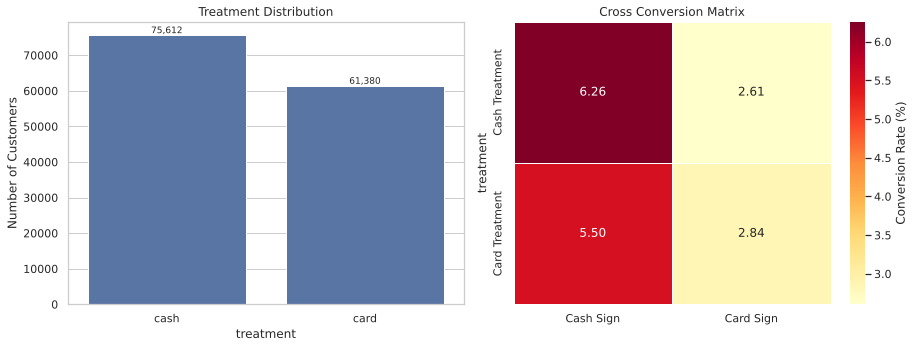

,Cash Sign,Card Sign
treatment,,
Cash Treatment,6.26,2.61
Card Treatment,5.50,2.84


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=treat.index, y=treat.values, ax=axes[0])
annotate_bars(axes[0], fmt="{:,.0f}")
axes[0].set_title("Treatment Distribution")
axes[0].set_ylabel("Number of Customers")
cross = pd.DataFrame({
    "Cash Sign": df.groupby(C.TREATMENT)[C.TARGET_CASH].mean() * 100,
    "Card Sign": df.groupby(C.TREATMENT)[C.TARGET_CARD].mean() * 100,
}).loc[["cash", "card"]].rename(index={"cash": "Cash Treatment", "card": "Card Treatment"})
sns.heatmap(cross, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=0.5, cbar_kws={"label": "Conversion Rate (%)"}, ax=axes[1])
axes[1].set_title("Cross Conversion Matrix")
fig.tight_layout()
fig.savefig(FIG / "eda_treatment_cross_conversion.png", dpi=150, bbox_inches="tight")
plt.show()
cross.round(2)

In [4]:
df[C.TARGETS].mean().mul(100).round(2).rename("overall_conversion_%")

cash_sign_30d    5.92
card_sign_30d    2.71
Name: overall_conversion_%, dtype: float64

## 2. Phân bố feature

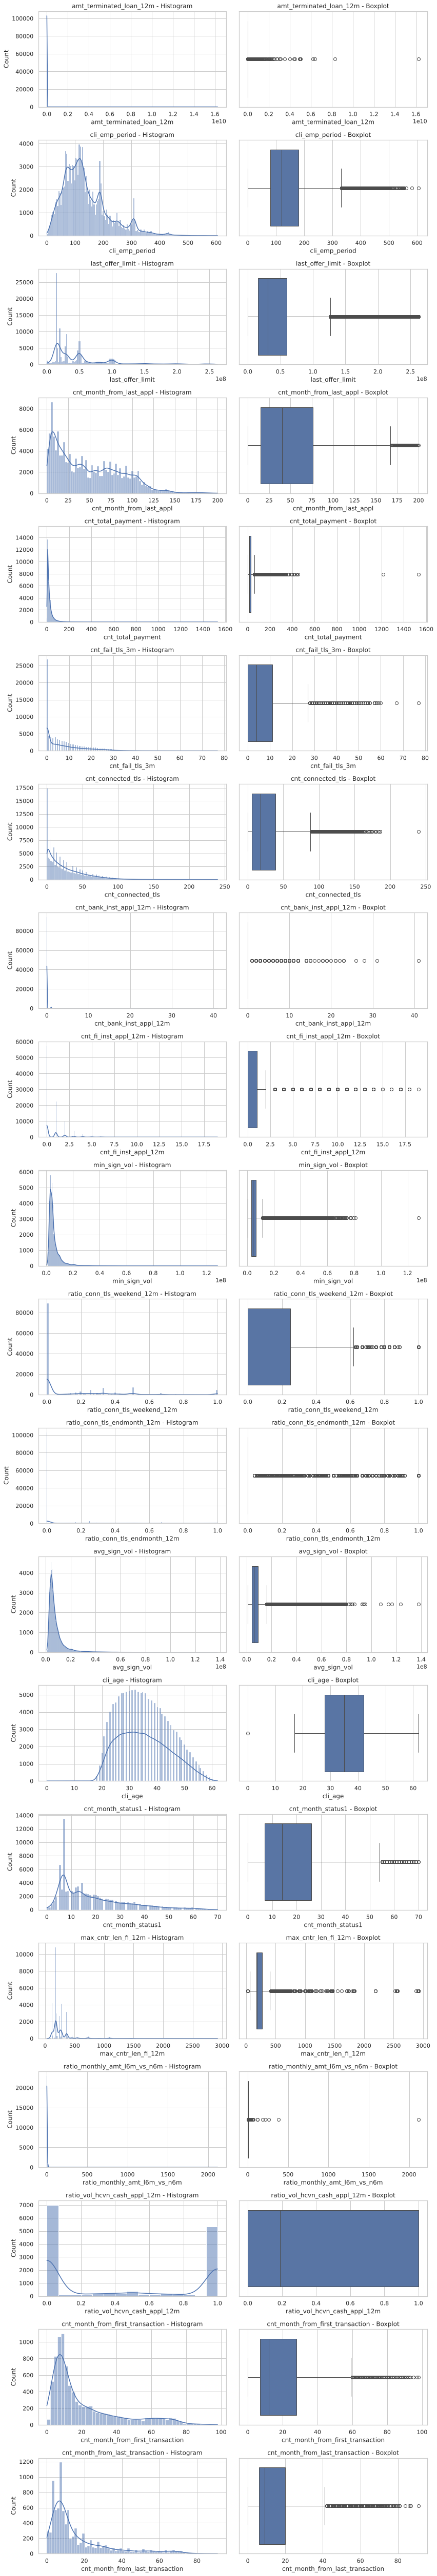

In [5]:
num_cont = C.NUM_CONT_COLS + [c for c in C.HIGH_MISSING_COLS if c != "f_appointment_3m"]
fig, axes = plt.subplots(len(num_cont), 2, figsize=(12, 3.5 * len(num_cont)))
for i, col in enumerate(num_cont):
    data = df[col].dropna()
    sns.histplot(data, kde=True, ax=axes[i, 0])
    sns.boxplot(x=data, ax=axes[i, 1])
    axes[i, 0].set_title(f"{col} - Histogram")
    axes[i, 1].set_title(f"{col} - Boxplot")
fig.tight_layout()
plt.show()

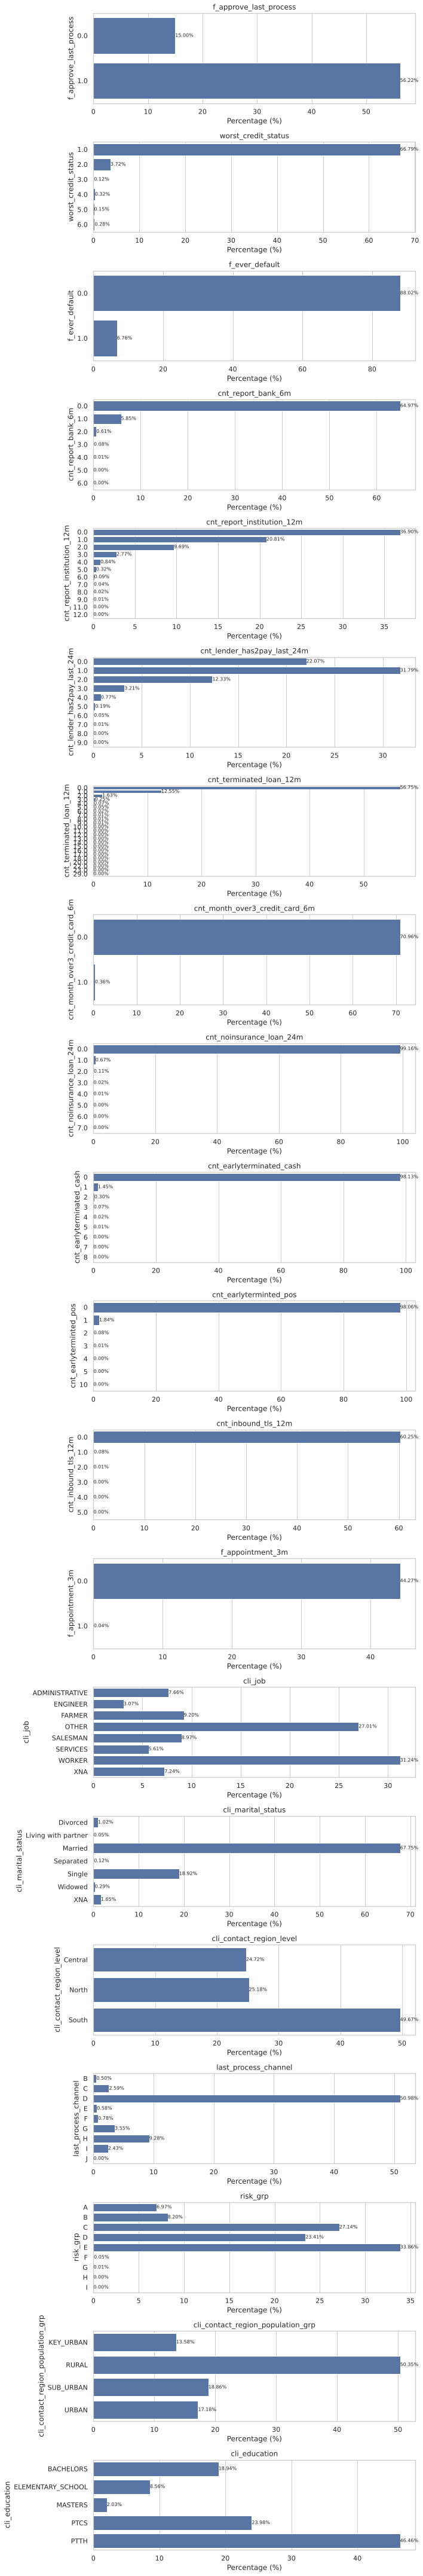

In [6]:
discrete = C.NUM_CAT_COLS + ["f_appointment_3m"] + C.NOMINAL_COLS[1:] + C.ORDINAL_COLS
fig, axes = plt.subplots(len(discrete), 1, figsize=(10, 3 * len(discrete)))
for ax, col in zip(axes, discrete):
    pct = df[col].value_counts(normalize=True, dropna=False).mul(100).sort_index()
    sns.barplot(x=pct.values, y=pct.index.astype(str), ax=ax)
    annotate_bars(ax, horizontal=True, fontsize=8)
    ax.set_title(col)
    ax.set_xlabel("Percentage (%)")
fig.tight_layout()
plt.show()

## 3. Chân dung khách hàng

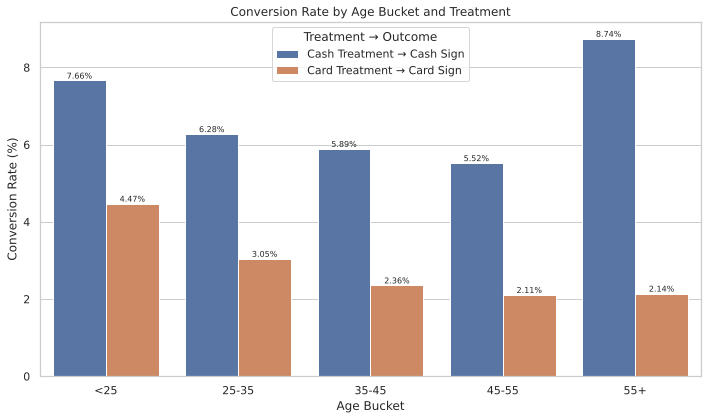

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
age_bucket,,,,
<25,7.66,4.47,3.19,17324
25-35,6.28,3.05,3.23,50880
35-45,5.89,2.36,3.54,43796
45-55,5.52,2.11,3.41,22062
55+,8.74,2.14,6.60,2930


In [7]:
age = matched_conversion(df, "age_bucket")
matched_conversion_bar(age, "Conversion Rate by Age Bucket and Treatment", "Age Bucket", save=FIG / "eda_age_bucket.png")
age.round(2)

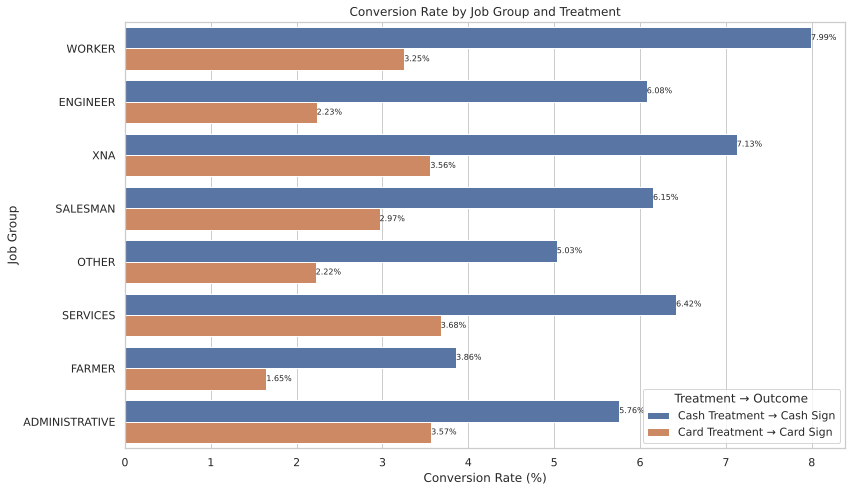

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
cli_job,,,,
WORKER,7.99,3.25,4.74,42792
ENGINEER,6.08,2.23,3.84,4201
XNA,7.13,3.56,3.57,9914
SALESMAN,6.15,2.97,3.19,12293
OTHER,5.03,2.22,2.81,37008
SERVICES,6.42,3.68,2.74,7686
FARMER,3.86,1.65,2.21,12604
ADMINISTRATIVE,5.76,3.57,2.19,10494


In [8]:
job = matched_conversion(df, "cli_job").sort_values("cash_minus_card", ascending=False)
matched_conversion_bar(job, "Conversion Rate by Job Group and Treatment", "Job Group", horizontal=True)
job.round(2)

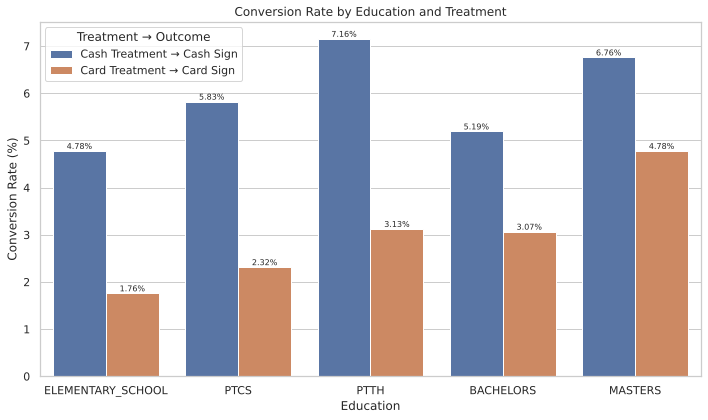

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
cli_education,,,,
ELEMENTARY_SCHOOL,4.78,1.76,3.02,11720
PTCS,5.83,2.32,3.51,32857
PTTH,7.16,3.13,4.03,63645
BACHELORS,5.19,3.07,2.13,25950
MASTERS,6.76,4.78,1.98,2778


In [9]:
edu = matched_conversion(df, "cli_education", C.EDUCATION_ORDER)
matched_conversion_bar(edu, "Conversion Rate by Education and Treatment", "Education")
edu.round(2)

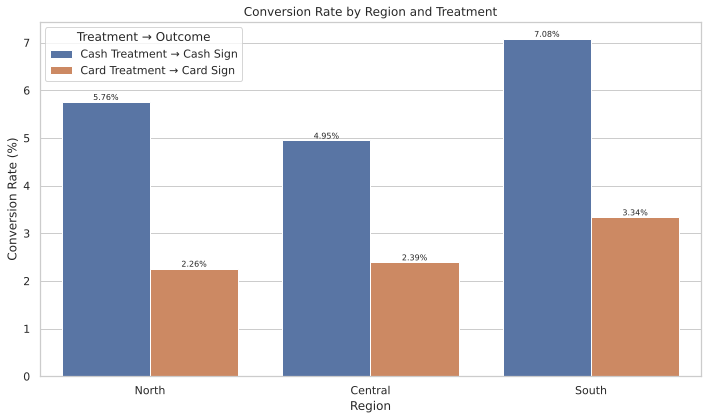

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
cli_contact_region_level,,,,
North,5.76,2.26,3.50,34495
Central,4.95,2.39,2.55,33868
South,7.08,3.34,3.74,68045


In [10]:
region = matched_conversion(df, "cli_contact_region_level", ["North", "Central", "South"])
matched_conversion_bar(region, "Conversion Rate by Region and Treatment", "Region")
region.round(2)

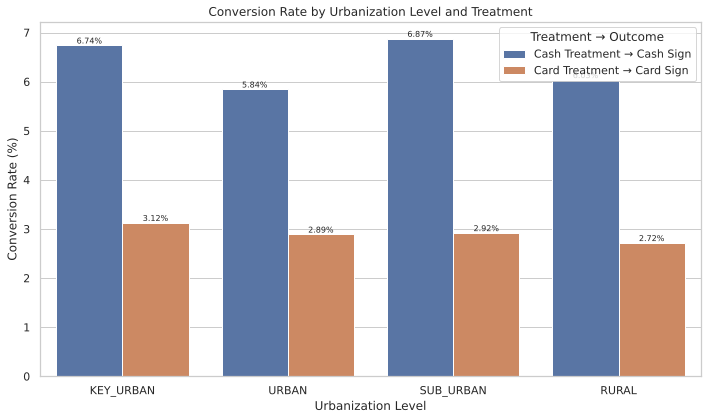

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
cli_contact_region_population_grp,,,,
KEY_URBAN,6.74,3.12,3.61,18602
URBAN,5.84,2.89,2.95,23536
SUB_URBAN,6.87,2.92,3.96,25843
RURAL,6.03,2.72,3.32,68969


In [11]:
urban = matched_conversion(df, "cli_contact_region_population_grp", ["KEY_URBAN", "URBAN", "SUB_URBAN", "RURAL"])
matched_conversion_bar(urban, "Conversion Rate by Urbanization Level and Treatment", "Urbanization Level")
urban.round(2)

## 4. Tín dụng và rủi ro

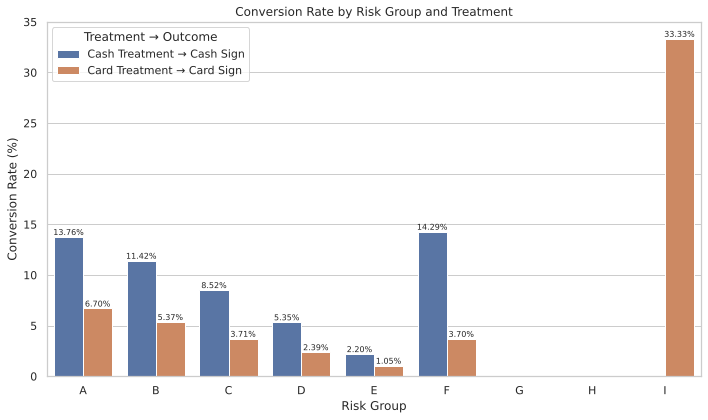

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
risk_grp,,,,
A,13.76,6.70,7.07,9553
B,11.42,5.37,6.05,11231
C,8.52,3.71,4.81,37179
D,5.35,2.39,2.96,32074
E,2.20,1.05,1.14,46381
F,14.29,3.70,10.58,69
G,0.00,0.00,0.00,13
H,0.00,0.00,0.00,5
I,0.00,33.33,-33.33,4


In [12]:
risk = matched_conversion(df, "risk_grp").sort_index()
matched_conversion_bar(risk, "Conversion Rate by Risk Group and Treatment", "Risk Group", save=FIG / "eda_risk_group.png")
risk.round(2)

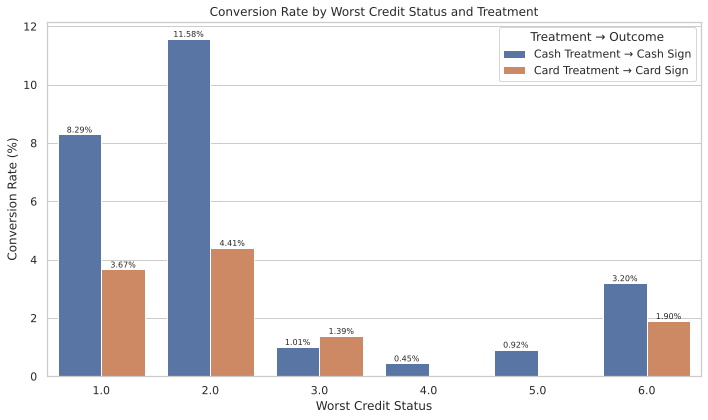

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
worst_credit_status,,,,
1.0,8.29,3.67,4.63,91493
2.0,11.58,4.41,7.17,5092
3.0,1.01,1.39,-0.38,171
4.0,0.45,0.00,0.45,432
5.0,0.92,0.00,0.92,210
6.0,3.20,1.90,1.30,377


In [13]:
credit = matched_conversion(df, "worst_credit_status").sort_index()
matched_conversion_bar(credit, "Conversion Rate by Worst Credit Status and Treatment", "Worst Credit Status")
credit.round(2)

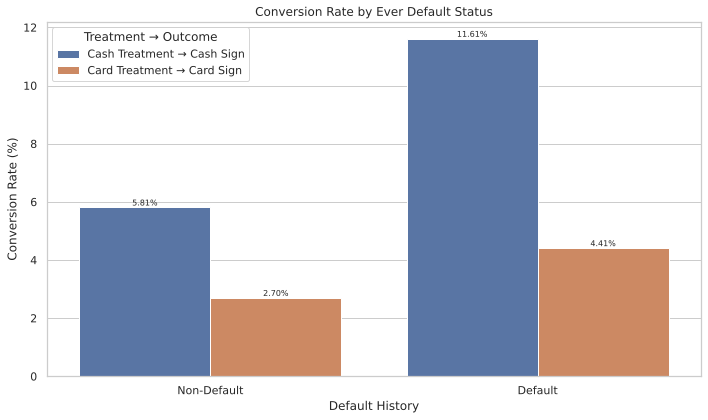

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
f_ever_default,,,,
Non-Default,5.81,2.70,3.11,120575
Default,11.61,4.41,7.20,9258


In [14]:
default = matched_conversion(df, "f_ever_default").rename(index={0: "Non-Default", 1: "Default"})
matched_conversion_bar(default, "Conversion Rate by Ever Default Status", "Default History")
default.round(2)

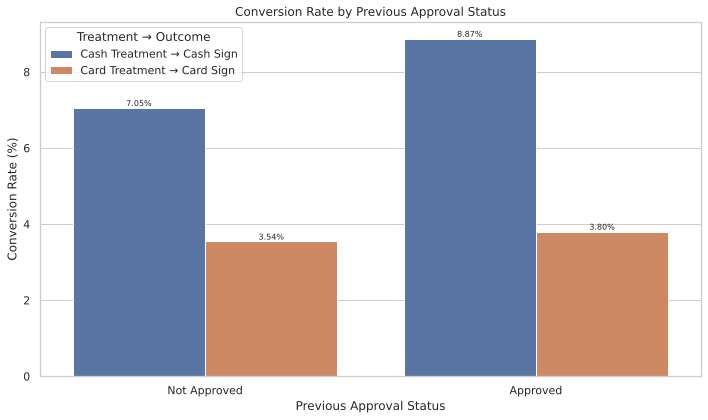

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
f_approve_last_process,,,,
Not Approved,7.05,3.54,3.51,20546
Approved,8.87,3.80,5.07,77016


In [15]:
approve = matched_conversion(df, "f_approve_last_process").rename(index={0: "Not Approved", 1: "Approved"})
matched_conversion_bar(approve, "Conversion Rate by Previous Approval Status", "Previous Approval Status")
approve.round(2)

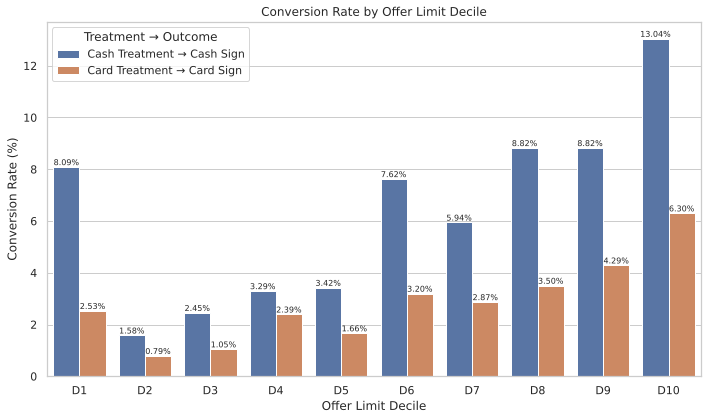

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
offer_limit_decile,,,,
D1,8.09,2.53,5.56,13702
D2,1.58,0.79,0.79,13682
D3,2.45,1.05,1.41,13682
D4,3.29,2.39,0.90,13687
D5,3.42,1.66,1.76,13691
D6,7.62,3.20,4.43,13689
D7,5.94,2.87,3.07,13686
D8,8.82,3.50,5.32,13686
D9,8.82,4.29,4.54,13688


In [16]:
limit = matched_conversion(df, "offer_limit_decile")
matched_conversion_bar(limit, "Conversion Rate by Offer Limit Decile", "Offer Limit Decile")
limit.round(2)

## 5. Giao dịch, telesales, tất toán

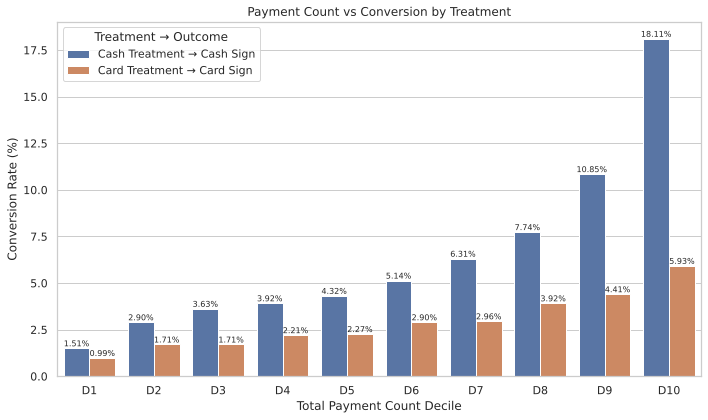

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
payment_decile,,,,
D1,1.51,0.99,0.52,22377
D2,2.90,1.71,1.19,11235
D3,3.63,1.71,1.92,10129
D4,3.92,2.21,1.71,14252
D5,4.32,2.27,2.05,12310
D6,5.14,2.90,2.23,12334
D7,6.31,2.96,3.36,13942
D8,7.74,3.92,3.82,13176
D9,10.85,4.41,6.44,13543


In [17]:
payment = matched_conversion(df, "payment_decile")
matched_conversion_bar(payment, "Payment Count vs Conversion by Treatment", "Total Payment Count Decile", save=FIG / "eda_payment_decile.png")
payment.round(2)

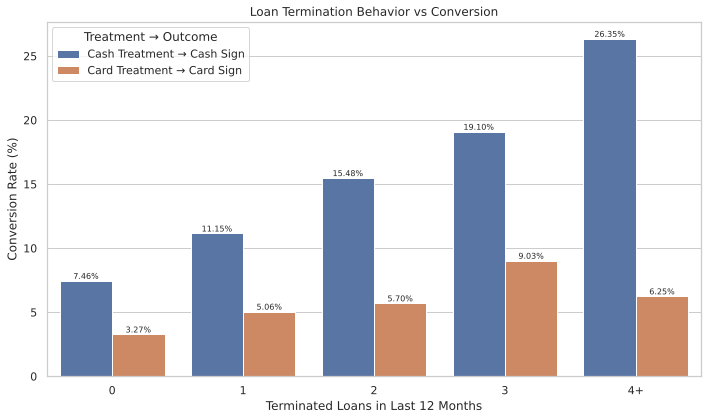

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
termination_bucket,,,,
0,7.46,3.27,4.18,77748
1,11.15,5.06,6.10,17197
2,15.48,5.70,9.78,2238
3,19.10,9.03,10.07,343
4+,26.35,6.25,20.10,260


In [18]:
termination = matched_conversion(df, "termination_bucket")
matched_conversion_bar(termination, "Loan Termination Behavior vs Conversion", "Terminated Loans in Last 12 Months", save=FIG / "eda_termination.png")
termination.round(2)

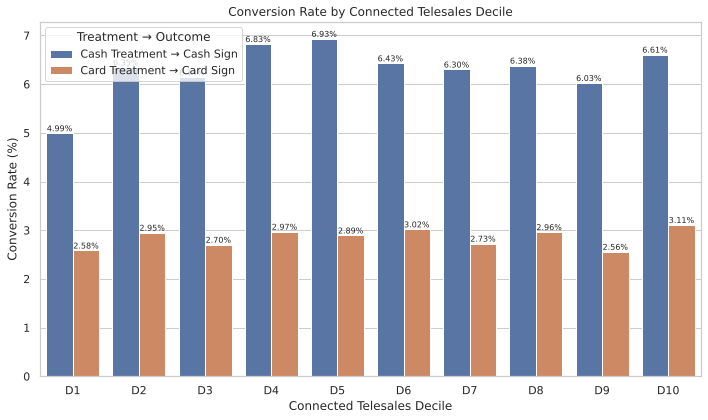

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
connected_tls_decile,,,,
D1,4.99,2.58,2.41,17372
D2,6.35,2.95,3.39,12082
D3,6.14,2.70,3.44,14141
D4,6.83,2.97,3.85,11725
D5,6.93,2.89,4.04,14500
D6,6.43,3.02,3.41,13822
D7,6.30,2.73,3.58,12470
D8,6.38,2.96,3.42,14461
D9,6.03,2.56,3.47,13170


In [19]:
tls = matched_conversion(df, "connected_tls_decile")
matched_conversion_bar(tls, "Conversion Rate by Connected Telesales Decile", "Connected Telesales Decile")
tls.round(2)

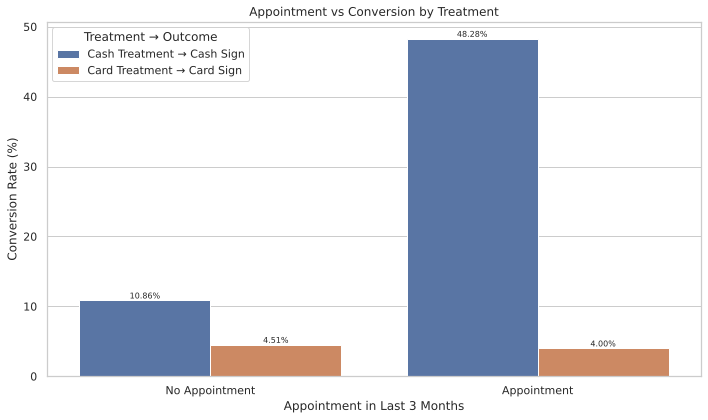

,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
f_appointment_3m,,,,
No Appointment,10.86,4.51,6.35,60640
Appointment,48.28,4.00,44.28,54


In [20]:
appointment = matched_conversion(df, "f_appointment_3m").rename(index={0: "No Appointment", 1: "Appointment"})
matched_conversion_bar(appointment, "Appointment vs Conversion by Treatment", "Appointment in Last 3 Months")
appointment.round(2)

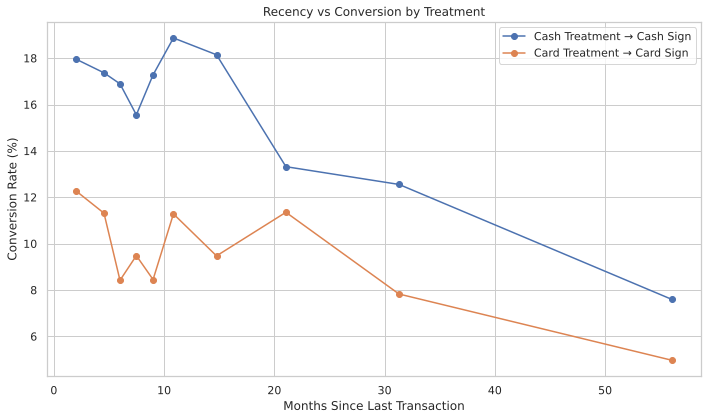

,avg_month_since_last_txn,Cash Treatment → Cash Sign,Card Treatment → Card Sign,cash_minus_card,n_customers
recency_decile,,,,,
D1,2.05,17.95,12.26,5.69,1050
D2,4.55,17.37,11.31,6.05,1042
D3,6.00,16.89,8.42,8.47,593
D4,7.48,15.56,9.48,6.07,1189
D5,9.00,17.28,8.45,8.83,556
D6,10.85,18.87,11.28,7.59,957
D7,14.76,18.15,9.47,8.68,866
D8,21.05,13.32,11.35,1.97,843
D9,31.31,12.55,7.83,4.73,815


In [21]:
recency = matched_conversion(df, "recency_decile")
recency.insert(0, "avg_month_since_last_txn", df.groupby("recency_decile", observed=False)["cnt_month_from_last_transaction"].mean())
fig, ax = plt.subplots(figsize=(10, 6))
for arm in ["Cash Treatment → Cash Sign", "Card Treatment → Card Sign"]:
    ax.plot(recency["avg_month_since_last_txn"], recency[arm], marker="o", label=arm)
ax.set_xlabel("Months Since Last Transaction")
ax.set_ylabel("Conversion Rate (%)")
ax.set_title("Recency vs Conversion by Treatment")
ax.legend()
fig.tight_layout()
plt.show()
recency.round(2)